# CNN Klassifikatoren mit Keras

In [ ]:
import pandas as pd
import os
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

from PIL import Image
from keras.layers import Dropout, Dense, Flatten, MaxPool2D, Conv2D, Resizing, GlobalAveragePooling2D, SpatialDropout2D
from keras.models import Sequential
from keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau
from keras.optimizers import Adam, RMSprop
from keras.utils import image_dataset_from_directory

import tensorflow as tf
from pathlib import Path
import shutil

2025-11-09 09:51:54.573138: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-09 09:51:54.671326: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1762678314.687879    1822 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1762678314.693174    1822 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1762678314.782787    1822 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
def plot_model_history(model_history):
    fig, axs = plt.subplots(1,2,figsize=(15,5))

    epochs = len(model_history.history['accuracy'])
    step = max(1, epochs // 5)

    axs[0].plot(range(1, epochs+1), model_history.history['accuracy'])
    axs[0].plot(range(1, epochs+1), model_history.history['val_accuracy'])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    axs[0].set_xticks(np.arange(1, epochs+1, step))
    axs[0].legend(['train', 'val'], loc='best')

    axs[1].plot(range(1, epochs+1), model_history.history['loss'])
    axs[1].plot(range(1, epochs+1), model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    axs[1].set_xticks(np.arange(1, epochs+1, step))
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()

import itertools
# Function to plot confusion matrix    
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

### Import von vorverarbeitetem Grunddatensatz

In [3]:
import re

# Load cleaned feature and target data
features = pd.read_csv('../data/features_cleaned.csv')
target = pd.read_csv('../data/target_cleaned.csv')

# Convert Windows paths to WSL2 compatible paths
def convert_to_wsl_path(windows_path):
    """Convert Windows path to WSL2 path"""
    path = str(windows_path)
    path = path.replace('\\', '/')
    path = re.sub(r'^([A-Z]):', lambda m: f'/mnt/{m.group(1).lower()}', path)
    return path

# 1D integer labels
label_vec = target.iloc[:, 0].astype(int).values
image_paths = [convert_to_wsl_path(p) for p in features['path'].tolist()]

# Stratified split on paths and labels
x_train_paths, x_test_paths, y_train_raw, y_test_raw = train_test_split(
    image_paths, label_vec, test_size=0.1, random_state=42, stratify=label_vec)

x_train_paths, x_validate_paths, y_train_raw, y_validate_raw = train_test_split(
    x_train_paths, y_train_raw, test_size=0.1, random_state=999, stratify=y_train_raw)

num_classes = 7
y_train = to_categorical(y_train_raw, num_classes=num_classes)
y_validate = to_categorical(y_validate_raw, num_classes=num_classes)
y_test = to_categorical(y_test_raw, num_classes=num_classes)

# Materialize split directories with class-named subfolders
# splits_root = Path('../data/splits')
# for split_name, paths, labels in [
#     ('train', x_train_paths, y_train_raw),
#     ('val',   x_validate_paths, y_validate_raw),
#     ('test',  x_test_paths, y_test_raw),
# ]:
#     for p, l in zip(paths, labels):
#         src = Path(p)
#         dst_dir = splits_root / split_name / str(int(l))
#         dst_dir.mkdir(parents=True, exist_ok=True)
#         dst = dst_dir / src.name
#         if not dst.exists():
#             try:
#                 os.symlink(src, dst)
#             except Exception:
#                 shutil.copy2(src, dst)


In [4]:
# Build datasets from the split directories using inferred labels
IMG_HEIGHT, IMG_WIDTH = 150, 200
BATCH_SIZE = 10

splits_root = Path('../data/splits')
train_ds = image_dataset_from_directory(
    splits_root / 'train',
    labels='inferred',
    label_mode='categorical',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42,
    interpolation='bilinear',
    follow_links=True  # follow symlinks to original files
)
val_ds = image_dataset_from_directory(
    splits_root / 'val',
    labels='inferred',
    label_mode='categorical',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False,
    interpolation='bilinear',
    follow_links=True  # follow symlinks to original files
)
test_ds = image_dataset_from_directory(
    splits_root / 'test',
    labels='inferred',
    label_mode='categorical',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False,
    interpolation='bilinear',
    follow_links=True  # follow symlinks to original files
)

# Normalize pixels and add prefetch; ignore unreadable files to avoid NotFoundError
AUTOTUNE = tf.data.AUTOTUNE
def normalize(x, y):
    return tf.cast(x, tf.float32) / 255.0, y

train_ds = (
    train_ds
    .map(normalize, num_parallel_calls=AUTOTUNE)
    .apply(tf.data.experimental.ignore_errors())  # drop bad records
    .prefetch(AUTOTUNE)
)
val_ds = (
    val_ds
    .map(normalize, num_parallel_calls=AUTOTUNE)
    .apply(tf.data.experimental.ignore_errors())
    .prefetch(AUTOTUNE)
)
test_ds = (
    test_ds
    .map(normalize, num_parallel_calls=AUTOTUNE)
    .apply(tf.data.experimental.ignore_errors())
    .prefetch(AUTOTUNE)
)

print('Data splits created:')
print('Train batches:', tf.data.experimental.cardinality(train_ds).numpy())
print('Val batches:', tf.data.experimental.cardinality(val_ds).numpy())
print('Test batches:', tf.data.experimental.cardinality(test_ds).numpy())

Found 8111 files belonging to 7 classes.


I0000 00:00:1762678344.597772    1822 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5660 MB memory:  -> device: 0, name: NVIDIA RTX A2000 8GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 902 files belonging to 7 classes.
Found 1002 files belonging to 7 classes.
Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.
Data splits created:
Train batches: -2
Val batches: -2
Test batches: -2


In [ ]:
num_classes = 7

model = Sequential()
model.add(Resizing(IMG_HEIGHT, IMG_WIDTH, interpolation='bilinear', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

model.add(Conv2D(32, 3, padding='same', activation='relu'))
model.add(Conv2D(32, 3, padding='same', activation='relu'))
model.add(MaxPool2D())
model.add(SpatialDropout2D(0.1))

model.add(Conv2D(64, 3, padding='same', activation='relu'))
model.add(Conv2D(64, 3, padding='same', activation='relu'))
model.add(MaxPool2D())
model.add(SpatialDropout2D(0.15))

model.add(Conv2D(128, 3, padding='same', activation='relu'))
model.add(Conv2D(128, 3, padding='same', activation='relu'))
model.add(MaxPool2D())

model.add(GlobalAveragePooling2D())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(num_classes, activation='softmax'))

model.summary()

/home/z004ps0b/miniforge3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resize (Resizing)               │ (None, 150, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 200, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 200, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 150, 200, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 150, 200, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 150, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 100, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 100, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 75, 100, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 37, 50, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,670,087 (29.26 MB)

 Trainable params: 7,670,087 (29.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = RMSprop(learning_rate=0.001, weight_decay=1e-6)

In [7]:
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
learning_rate_reduction = ReduceLROnPlateau(
    monitor='val_accuracy',
    patience=4,
    verbose=1,
    factor=0.5,
    min_lr=1e-5,
)

In [9]:
epochs = 40
history = model.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    verbose=1,
    callbacks=[learning_rate_reduction],
)

Epoch 1/40


I0000 00:00:1762678353.292846    2157 service.cc:152] XLA service 0x7a462400db70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762678353.292889    2157 service.cc:160]   StreamExecutor device (0): NVIDIA RTX A2000 8GB Laptop GPU, Compute Capability 8.6
2025-11-09 09:52:33.398355: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1762678353.695943    2157 cuda_dnn.cc:529] Loaded cuDNN version 91002
2025-11-09 09:52:42.675809: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng48{k0=9,k2=1,k5=2,k14=5} for conv %cudnn-conv-bw-filter.10 = (f32[64,32,3,3]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,32,150,200]{3,2,1,0} %bitcast.12001, f32[10,64,150,200]{3,2,1,0} %bitcast.12053), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardFilter", metadata={

      1/Unknown 15s 15s/step - accuracy: 0.2000 - loss: 1.9530

I0000 00:00:1762678366.917233    2157 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    812/Unknown 68s 65ms/step - accuracy: 0.6594 - loss: 1.2310

...

2025-11-09 10:26:42.331792: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 9879070361225960845
2025-11-09 10:26:42.331828: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 1618097620257162638


811/812 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.7026 - loss: 0.8345

2025-11-09 10:27:30.326416: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 9879070361225960845
2025-11-09 10:27:30.326450: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 1618097620257162638


812/812 ━━━━━━━━━━━━━━━━━━━━ 49s 61ms/step - accuracy: 0.7108 - loss: 0.8151 - val_accuracy: 0.6951 - val_loss: 0.8889 - learning_rate: 1.0000e-05


2025-11-09 10:27:31.751212: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 9879070361225960845
2025-11-09 10:27:31.751255: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 1618097620257162638


In [10]:
loss, accuracy = model.evaluate(test_ds, verbose=1)
loss_v, accuracy_v = model.evaluate(val_ds, verbose=1)
print('Validation: accuracy = %f  ;  loss_v = %f' % (accuracy_v, loss_v))
print('Test: accuracy = %f  ;  loss = %f' % (accuracy, loss))
model.save('../models/model.keras')

101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6896 - loss: 0.8572
      7/Unknown 0s 17ms/step - accuracy: 0.0020 - loss: 3.1461    

2025-11-09 10:27:33.463461: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 9879070361225960845
2025-11-09 10:27:33.463504: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 1618097620257162638


91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6951 - loss: 0.8889
Validation: accuracy = 0.695122  ;  loss_v = 0.888916
Test: accuracy = 0.689621  ;  loss = 0.857204


2025-11-09 10:27:34.940661: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 9879070361225960845
2025-11-09 10:27:34.940707: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 1618097620257162638


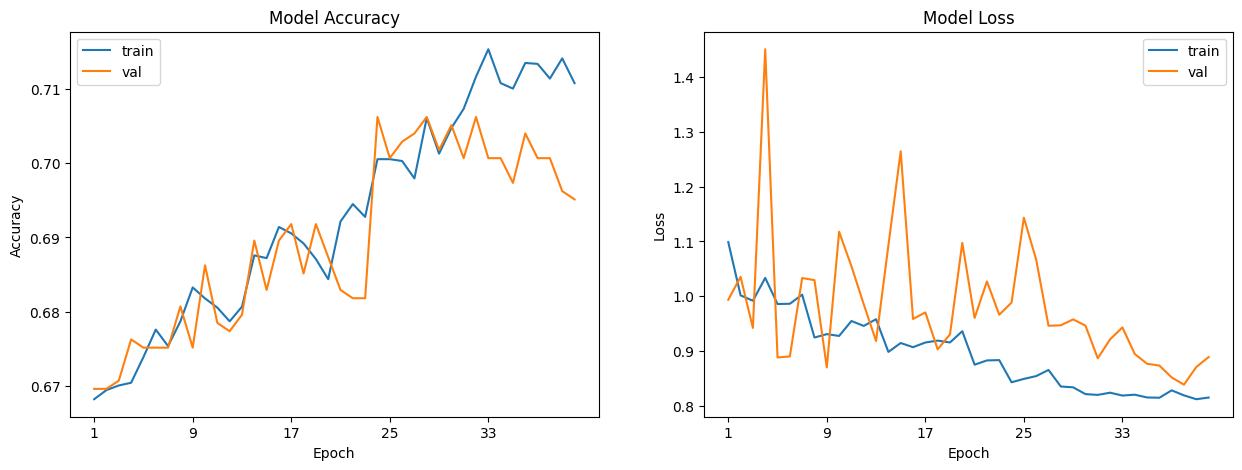

In [11]:
plot_model_history(history)

101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step


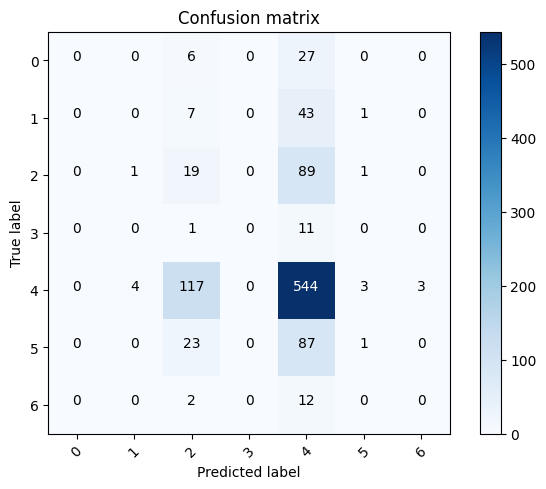

In [12]:
# Predict the values from the test dataset
Y_pred = model.predict(test_ds)
Y_pred_classes = np.argmax(Y_pred, axis=1)
Y_true = y_test_raw
confusion_mtx = confusion_matrix(Y_true, Y_pred_classes)
plot_confusion_matrix(confusion_mtx, classes=range(num_classes))

In [13]:
from sklearn.metrics import f1_score

# Calculate F1 scores for each class
f1_scores = f1_score(Y_true, Y_pred_classes, average=None)

# Print F1 scores per class
for class_idx, f1 in enumerate(f1_scores):
    print(f'Class {class_idx}: F1 = {f1:.4f}')

# Print weighted and macro average F1 scores
f1_weighted = f1_score(Y_true, Y_pred_classes, average='weighted')
f1_macro = f1_score(Y_true, Y_pred_classes, average='macro')

print(f'\nWeighted F1 Score: {f1_weighted:.4f}')
print(f'Macro F1 Score: {f1_macro:.4f}')

Class 0: F1 = 0.0000
Class 1: F1 = 0.0000
Class 2: F1 = 0.1333
Class 3: F1 = 0.0000
Class 4: F1 = 0.7332
Class 5: F1 = 0.0171
Class 6: F1 = 0.0000

Weighted F1 Score: 0.5075
Macro F1 Score: 0.1262
